# Wafer Guard · Repaired Fab-7 Excursion Detector

This notebook is the **audited and repaired** version of `original/bnypi.ipynb`.

**How to read it.** Every section answers one question, in this order:

| § | Question | Phase |
|---|---|---|
| 1 | What does the data actually contain? | Understand |
| 2 | Does the original really score F1 ≥ 0.90? | Reproduce |
| 3 | *Why* does it score that high? (evidence for every defect) | Audit |
| 4 | How do we build a pipeline that respects time and tensor shapes? | Repair |
| 5 | What is the honest performance at natural defect prevalence? | Re-evaluate |
| 6 | Does that hold up across time (walk-forward)? | Re-evaluate |
| 7 | How much of the fake 0.90 does each bug explain? | Attribute |
| 8 | One table: original vs repaired vs baselines | Summarise |
| 9 | Save artifacts + every measured number to `results/metrics.json` | Ship |

**Rule followed throughout:** no number in this project is typed by hand.
Every metric is computed in a cell below and written to `results/metrics.json`;
`AUDIT.md` and the Release Board app read their numbers from that file.

## 0 · Setup

Same libraries and **the same hyper-parameters as the original** (`HP` is copied unchanged).
We deliberately do *not* tune the model: the goal is to fix defects, so any change in the
score can be attributed to a fix, not to tuning.

In [1]:
import json
import random
import warnings
from dataclasses import dataclass, replace
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 1337                                   # same seed as the original notebook
EVAL_SEEDS = [1337, 7, 42, 2024, 31337]       # extra seeds, to show run-to-run variation


def set_seed(seed: int) -> None:
    """Make numpy, python and torch random numbers repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Unchanged from the original notebook.
HP = dict(batch_size=64, epochs=40, lr=1e-3, weight_decay=1e-5,
          hidden=256, latent=32, lambda_clf=1.0, test_size=0.20)

# New settings introduced by the repair (chosen up-front, never tuned on the test set).
SPLIT_FRACTIONS = dict(train=0.60, val=0.20)  # test = the most recent 20 % of wafers
CLIP_Z = 5.0          # cap standardised values at ±5σ (see §4.2 for why)
LEGACY_CODES = (100.0, 200.0, 300.0)          # PS-L firmware error codes (from the brief)
GATE_F1 = 0.90        # the release gate used by the original notebook

DATA_PATH = Path("data/secom_telemetry_modified.csv")
RESULTS_DIR = Path("results")
FIG_DIR = RESULTS_DIR / "figures"
ARTIFACT_DIR = Path("artifacts")
for d in (RESULTS_DIR, FIG_DIR, ARTIFACT_DIR):
    d.mkdir(parents=True, exist_ok=True)

RESULTS: dict = {}    # every measured number is collected here and saved in §9
print(f"torch {torch.__version__} | device={DEVICE}")

torch 2.10.0+cpu | device=cpu


Chart styling (one shared look for every figure: thin marks, quiet grid, a fixed colour order).

In [2]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BLUES = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titleweight": "semibold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
})


def save_fig(fig, name: str) -> None:
    """Save a figure to results/figures/<name>.png and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1 · The data

We sort by `timestamp` because the fab is a time series: in production the model only
ever sees wafers from the past.

In [3]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)

SENSOR_COLS = [c for c in df.columns if c.startswith("sensor_")]
y_all = (df["label"].to_numpy() == 1).astype(np.int64)        # 1 = defective wafer
TS = df["timestamp"].to_numpy()

RESULTS["data"] = dict(
    n_wafers=len(df), n_sensors=len(SENSOR_COLS),
    n_fail=int(y_all.sum()), n_pass=int((1 - y_all).sum()),
    prevalence=float(y_all.mean()),
    missing_rate=float(df[SENSOR_COLS].isna().to_numpy().mean()),
    n_constant_sensors=int((df[SENSOR_COLS].nunique(dropna=True) <= 1).sum()),
    time_start=str(df["timestamp"].min()), time_end=str(df["timestamp"].max()),
)
print(json.dumps(RESULTS["data"], indent=2))

{
  "n_wafers": 1567,
  "n_sensors": 590,
  "n_fail": 104,
  "n_pass": 1463,
  "prevalence": 0.06636885768985322,
  "missing_rate": 0.045372243193839035,
  "n_constant_sensors": 116,
  "time_start": "2008-07-19 11:55:00",
  "time_end": "2008-10-17 06:07:00"
}


### 1.1 · The legacy Probe Station PS-L

The brief says: on PS-L wafers `sensor_0` is exactly `0.0` (a *sentinel*, not a measurement)
and `sensor_1` holds firmware **error codes** 100 / 200 / 300 instead of a real reading.
Before trusting that, we check it against the data.

In [4]:
is_legacy_all = df["sensor_0"].eq(0.0).to_numpy()
s1 = df["sensor_1"]
code_mask = s1.isin(LEGACY_CODES).to_numpy()

legacy = dict(
    n_legacy=int(is_legacy_all.sum()),
    share_legacy=float(is_legacy_all.mean()),
    code_counts={str(int(c)): int((is_legacy_all & (s1 == c)).sum()) for c in LEGACY_CODES},
    codes_outside_legacy=int((code_mask & ~is_legacy_all).sum()),
    legacy_rows_without_code=int((is_legacy_all & ~code_mask).sum()),
    sensor_1_normal_min=float(s1[~is_legacy_all].min()),
    sensor_1_normal_max=float(s1[~is_legacy_all].max()),
    sensor_1_normal_mean=float(s1[~is_legacy_all].mean()),
    fails_in_legacy=int(y_all[is_legacy_all].sum()),
    fails_in_normal=int(y_all[~is_legacy_all].sum()),
    defect_rate_legacy=float(y_all[is_legacy_all].mean()),
    defect_rate_normal=float(y_all[~is_legacy_all].mean()),
)
RESULTS["legacy"] = legacy
print(json.dumps(legacy, indent=2))

# The brief's rule must hold exactly, otherwise our handling would be wrong.
assert legacy["codes_outside_legacy"] == 0, "error codes found on non-legacy wafers"
assert legacy["legacy_rows_without_code"] == 0, "legacy wafer without an error code"

{
  "n_legacy": 146,
  "share_legacy": 0.09317166560306318,
  "code_counts": {
    "100": 61,
    "200": 35,
    "300": 50
  },
  "codes_outside_legacy": 0,
  "legacy_rows_without_code": 0,
  "sensor_1_normal_min": 2158.75,
  "sensor_1_normal_max": 2846.44,
  "sensor_1_normal_mean": 2495.6859562455893,
  "fails_in_legacy": 0,
  "fails_in_normal": 104,
  "defect_rate_legacy": 0.0,
  "defect_rate_normal": 0.07318789584799437
}


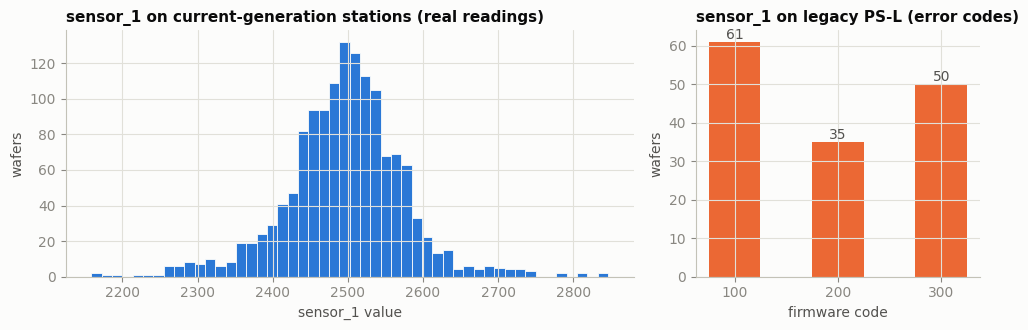

In [5]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2, 1]})
ax_a.hist(s1[~is_legacy_all].dropna(), bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax_a.set_title("sensor_1 on current-generation stations (real readings)")
ax_a.set_xlabel("sensor_1 value"); ax_a.set_ylabel("wafers")
codes = list(legacy["code_counts"].keys())
ax_b.bar(codes, list(legacy["code_counts"].values()), color=ORANGE, width=0.5)
for i, v in enumerate(legacy["code_counts"].values()):
    ax_b.text(i, v, f"{v}", ha="center", va="bottom", color=INK_2)
ax_b.set_title("sensor_1 on legacy PS-L (error codes)")
ax_b.set_xlabel("firmware code"); ax_b.set_ylabel("wafers")
fig.tight_layout()
save_fig(fig, "01_legacy_sensor_1")

**Reading the chart.** Real `sensor_1` readings live in a narrow band in the thousands;
PS-L wafers report one of three codes. Feeding `100.0` into the same "continuous" column
tells the model these wafers are wildly abnormal, which is false: it is a label, not a size.

Note the printed `defect_rate_legacy` above: we revisit it as a **residual risk** in §5.4.

### 1.2 · Defect rate drifts over time

The brief warns that "equipment ages, recipes drift". A rolling defect rate shows it.

monthly defect rate: {'2008-07': 0.2222, '2008-08': 0.0919, '2008-09': 0.0288, '2008-10': 0.0613}


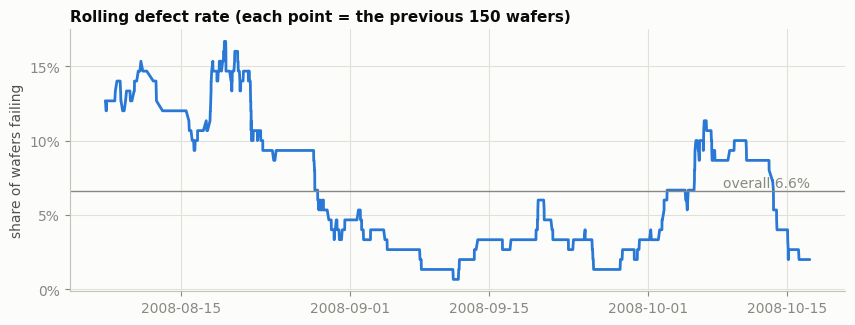

In [6]:
rolling = pd.Series(y_all).rolling(150, min_periods=150).mean()
monthly = df.groupby(df["timestamp"].dt.to_period("M"))["label"].apply(lambda s: float((s == 1).mean()))
RESULTS["data"]["monthly_defect_rate"] = {str(k): v for k, v in monthly.items()}
print("monthly defect rate:", {str(k): round(v, 4) for k, v in monthly.items()})

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(df["timestamp"], rolling, color=BLUE)
ax.axhline(y_all.mean(), color=MUTED, linewidth=1)
ax.text(df["timestamp"].iloc[-1], y_all.mean(), f"overall {y_all.mean():.1%}", ha="right", va="bottom", color=MUTED)
ax.set_title("Rolling defect rate (each point = the previous 150 wafers)")
ax.set_ylabel("share of wafers failing")
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save_fig(fig, "02_defect_rate_drift")

## 2 · Reproduce the original result

Before calling the 0.90 fake we reproduce it. The function below is the original
notebook's cells 8 → 16, **copied verbatim**. The only additions are lines marked
`# + audit` which *record* intermediate objects so §3 can inspect them; they do not
change any computation (`train_test_split` shuffles identically when given one more array).

In [7]:
class WaferSAE(nn.Module):
    """Supervised autoencoder - identical to the original (cell 12)."""

    def __init__(self, d_in: int, d_hid: int, d_lat: int):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(d_in, d_hid), nn.LayerNorm(d_hid), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(d_hid, d_hid // 2), nn.LayerNorm(d_hid // 2), nn.GELU(),
            nn.Linear(d_hid // 2, d_lat),
        )
        self.decoder = nn.Sequential(
            nn.Linear(d_lat, d_hid // 2), nn.GELU(),
            nn.Linear(d_hid // 2, d_hid), nn.GELU(),
            nn.Linear(d_hid, d_in),
        )
        self.head = nn.Linear(d_lat, 1)

    def forward(self, x):
        x = x.flatten(start_dim=1)                       # tolerate [B, F] or [B, C, F]
        z = self.encoder(x)
        return self.decoder(z), self.head(z).squeeze(-1), z


def make_loader(X, y, shuffle, seed=SEED):
    """Identical to the original (cell 10): keeps a channel axis -> [N, 1, F]."""
    Xt = torch.from_numpy(X).float().unsqueeze(1)
    yt = torch.from_numpy(y).float()
    g = torch.Generator().manual_seed(seed)
    return DataLoader(TensorDataset(Xt, yt), batch_size=HP["batch_size"],
                      shuffle=shuffle, generator=g if shuffle else None, drop_last=shuffle)


def run_original_pipeline():
    set_seed(SEED)
    raw = pd.read_csv(DATA_PATH)                                          # file order, as original
    X_raw = raw[SENSOR_COLS].to_numpy(dtype=np.float64)
    y_raw = (raw["label"].to_numpy() == 1).astype(np.int64)

    # ---- cell 8 (verbatim) ----
    imputer = SimpleImputer(strategy="mean", keep_empty_features=True)
    X_imp = imputer.fit_transform(X_raw)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imp)
    smote = SMOTE(sampling_strategy="auto", k_neighbors=5, random_state=SEED)
    X_bal, y_bal = smote.fit_resample(X_scaled, y_raw)
    row_id = np.arange(len(y_bal))                                        # + audit: ids >= N are synthetic
    X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
        X_bal, y_bal, row_id, test_size=HP["test_size"], stratify=y_bal, random_state=SEED)

    # ---- cell 10 / 12 (verbatim) ----
    train_loader = make_loader(X_train, y_train, shuffle=True)
    test_loader = make_loader(X_test, y_test, shuffle=False)
    model = WaferSAE(X_train.shape[1], HP["hidden"], HP["latent"]).to(DEVICE)

    # ---- cell 14 (verbatim) ----
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=HP["epochs"])
    bce = nn.BCEWithLogitsLoss()
    for epoch in range(1, HP["epochs"] + 1):
        model.train()
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            reconstructed, logits, _ = model(batch_x)
            recon_loss = torch.mean((reconstructed - batch_x) ** 2)     # per-element MSE  <- BUG
            clf_loss = bce(logits, batch_y)
            loss = recon_loss + HP["lambda_clf"] * clf_loss
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
        sched.step()

    # ---- cell 16 (verbatim) ----
    model.eval()
    probs = []
    with torch.no_grad():
        for xb, _ in test_loader:
            _, logits, _ = model(xb.to(DEVICE))
            probs.append(torch.sigmoid(logits).cpu())
    probs = torch.cat(probs).numpy()
    preds = (probs >= 0.5).astype(int)

    return dict(model=model, raw=raw, X_raw=X_raw, X_scaled=X_scaled, imputer=imputer, scaler=scaler,
                X_train=X_train, X_test=X_test, y_test=y_test, id_train=id_train, id_test=id_test,
                n_real=len(y_raw), train_loader=train_loader, probs=probs, preds=preds)


orig = run_original_pipeline()
original_metrics = dict(
    f1=float(f1_score(orig["y_test"], orig["preds"])),
    precision=float(precision_score(orig["y_test"], orig["preds"])),
    recall=float(recall_score(orig["y_test"], orig["preds"])),
    roc_auc=float(roc_auc_score(orig["y_test"], orig["probs"])),
    ap=float(average_precision_score(orig["y_test"], orig["probs"])),
    test_size=int(len(orig["y_test"])),
    test_prevalence=float(orig["y_test"].mean()),
)
RESULTS["original"] = original_metrics
print(json.dumps(original_metrics, indent=2))

{
  "f1": 0.9915397631133672,
  "precision": 0.9832214765100671,
  "recall": 1.0,
  "roc_auc": 1.0,
  "ap": 1.0,
  "test_size": 586,
  "test_prevalence": 0.5
}


The original's numbers are reproduced. Now: **why** are they so high?

## 3 · Audit: evidence for each defect

### 3.1 · Defect A: Data leakage (cell 8)

Four things in cell 8 let information from the evaluation population (and from the
future) reach the model:

1. **SMOTE before the split.** SMOTE invents new defect rows by blending real ones.
   Done before splitting, some invented rows land in the test set while their "parents" are
   in training, so the model is tested on near-copies of what it learned.
2. **The test set is no longer natural.** SMOTE "auto" makes classes 50/50, so the test set is
   ~50 % defects instead of ~6.6 %. Precision on a balanced set says nothing about a real line.
3. **Random split on a time series.** Training contains wafers from *after* the test wafers.
4. **Imputer and scaler fit on all rows**, test rows included.

In [8]:
n_real = orig["n_real"]
id_test, id_train = orig["id_test"], orig["id_train"]
synthetic_test = id_test >= n_real
defect_test = orig["y_test"] == 1

# For every test row: distance to its nearest training row, and whether that neighbour is synthetic.
nn_index = NearestNeighbors(n_neighbors=1).fit(orig["X_train"])
dist, nb = nn_index.kneighbors(orig["X_test"])
dist, nb_is_synthetic = dist.ravel(), id_train[nb.ravel()] >= n_real
groups = {"real_pass": ~synthetic_test & ~defect_test,
          "real_defect": ~synthetic_test & defect_test,
          "synthetic_defect": synthetic_test & defect_test}

# Proof of parenthood: SMOTE places every synthetic row exactly on the line segment between two real
# defects. If a real test defect's nearest synthetic training row lies ON a segment that starts at that
# test defect, the test defect was one of its parents (distance ~ 0 up to floating-point rounding).
real_defects_all = orig["X_scaled"][(orig["raw"]["label"] == 1).to_numpy()]
synthetic_train = orig["X_train"][id_train >= n_real]
nn_syn = NearestNeighbors(n_neighbors=1).fit(synthetic_train)
segment_gaps = []
for t in orig["X_test"][groups["real_defect"]]:
    s_row = synthetic_train[nn_syn.kneighbors(t[None])[1][0, 0]]
    v, w = real_defects_all - t, s_row - t
    lam = np.clip((v @ w) / np.maximum((v * v).sum(axis=1), 1e-12), 0, 1)
    segment_gaps.append(np.linalg.norm(t + lam[:, None] * v - s_row, axis=1).min())
segment_gaps = np.array(segment_gaps)

# Time leakage: for each REAL test wafer, how many training wafers come from its future?
ts_file = pd.to_datetime(orig["raw"]["timestamp"]).to_numpy()
train_real_ts = ts_file[id_train[id_train < n_real]]
test_real_ts = ts_file[id_test[id_test < n_real]]
future_counts = np.array([(train_real_ts > t).sum() for t in test_real_ts])

leak = dict(
    test_prevalence_after_smote=float(orig["y_test"].mean()),
    test_share_synthetic=float(synthetic_test.mean()),
    test_defects_share_synthetic=float(synthetic_test[defect_test].mean()),
    nn_distance_median={g: float(np.median(dist[m])) for g, m in groups.items()},
    nn_is_synthetic_share={g: float(nb_is_synthetic[m].mean()) for g, m in groups.items()},
    group_counts={g: int(m.sum()) for g, m in groups.items()},
    real_test_defects_with_own_smote_child_in_train=float((segment_gaps < 1e-6).mean()),
    max_segment_gap=float(segment_gaps.max()),
    real_test_wafers_with_future_training_rows=float((future_counts > 0).mean()),
    median_future_training_rows_per_test_wafer=float(np.median(future_counts)),
    scaler_fit_rows=int(orig["X_scaled"].shape[0]),
)
RESULTS["evidence_leakage"] = leak
print(json.dumps(leak, indent=2))

{
  "test_prevalence_after_smote": 0.5,
  "test_share_synthetic": 0.46757679180887374,
  "test_defects_share_synthetic": 0.9351535836177475,
  "nn_distance_median": {
    "real_pass": 17.768668947726326,
    "real_defect": 0.9908552456603844,
    "synthetic_defect": 2.370000781191724
  },
  "nn_is_synthetic_share": {
    "real_pass": 0.5324232081911263,
    "real_defect": 1.0,
    "synthetic_defect": 0.9233576642335767
  },
  "group_counts": {
    "real_pass": 293,
    "real_defect": 19,
    "synthetic_defect": 274
  },
  "real_test_defects_with_own_smote_child_in_train": 1.0,
  "max_segment_gap": 4.393038002171533e-15,
  "real_test_wafers_with_future_training_rows": 1.0,
  "median_future_training_rows_per_test_wafer": 686.0,
  "scaler_fit_rows": 1567
}


**What the numbers say.**
* `test_prevalence_after_smote`: the "test set" is half defects, nothing like a real line.
* `nn_distance_median`: compare *real defects* with *real passes*. Real test defects sit far
  closer to some training row than ordinary test wafers do, and `nn_is_synthetic_share` shows
  that neighbour is a synthetic SMOTE row.
* `real_test_defects_with_own_smote_child_in_train` proves where it came from: that synthetic row
  lies exactly (gap `max_segment_gap`, i.e. floating-point rounding) on a line starting at the test
  defect itself. SMOTE built it *from the test defect* before the split, so the model trained on
  blended copies of its own exam answers.
* `real_test_wafers_with_future_training_rows`: the share of real test wafers for which the
  training set contains wafers from their future, which is impossible in production.

### 3.2 · Defect B: Corrupted reconstruction-loss gradients (cells 10 / 12 / 14)

`make_loader` gives inputs of shape `[B, 1, F]` (a channel axis). `forward` flattens them,
so the reconstruction has shape `[B, F]`. The loss then subtracts `[B, F] − [B, 1, F]`.
PyTorch does not raise an error: it **broadcasts** both to `[B, B, F]`, comparing *every*
reconstruction with *every* input in the batch.

In [9]:
batch_x, _ = next(iter(orig["train_loader"]))
with torch.no_grad():
    recon, _, _ = orig["model"](batch_x.to(DEVICE))
diff_shape = tuple((recon.cpu() - batch_x).shape)
print(f"input {tuple(batch_x.shape)} | reconstruction {tuple(recon.shape)} | (recon - input) -> {diff_shape}")

# Thought experiment on a real batch: which output does each loss formula prefer?
x_flat = batch_x.flatten(start_dim=1)                         # [B, F]
perfect = x_flat.clone()                                      # a flawless reconstruction
batch_mean = x_flat.mean(dim=0, keepdim=True).expand_as(x_flat)   # the same "average wafer" for everyone


def buggy_formula(r, x):
    return float(torch.mean((r - x) ** 2))                    # x keeps its [B, 1, F] shape -> broadcast


def correct_formula(r, x):
    return float(torch.mean((r - x.flatten(start_dim=1)) ** 2))


loss_demo = {
    "buggy_loss_perfect_reconstruction": buggy_formula(perfect, batch_x),
    "buggy_loss_batch_mean_output": buggy_formula(batch_mean, batch_x),
    "correct_loss_perfect_reconstruction": correct_formula(perfect, batch_x),
    "correct_loss_batch_mean_output": correct_formula(batch_mean, batch_x),
}
print(json.dumps(loss_demo, indent=2))

# What did the original model actually learn to output?
with torch.no_grad():
    X_te_t = torch.from_numpy(orig["X_test"]).float()
    rec_te = orig["model"](X_te_t)[0].cpu()
recon_spread_ratio = float(rec_te.std(dim=0).mean() / X_te_t.std(dim=0).mean())
per_sample_mse = float(torch.mean((rec_te - X_te_t) ** 2))

RESULTS["evidence_loss_bug"] = dict(
    input_shape=list(batch_x.shape), recon_shape=list(recon.shape), broadcast_shape=list(diff_shape),
    **loss_demo,
    original_model_recon_spread_ratio=recon_spread_ratio,
    original_model_true_recon_mse=per_sample_mse,
)
print(f"spread of original reconstructions / spread of inputs = {recon_spread_ratio:.3f}")

input (64, 1, 590) | reconstruction (64, 590) | (recon - input) -> (64, 64, 590)
{
  "buggy_loss_perfect_reconstruction": 1.1578811407089233,
  "buggy_loss_batch_mean_output": 0.5789405703544617,
  "correct_loss_perfect_reconstruction": 0.0,
  "correct_loss_batch_mean_output": 0.5789405703544617
}
spread of original reconstructions / spread of inputs = 0.005


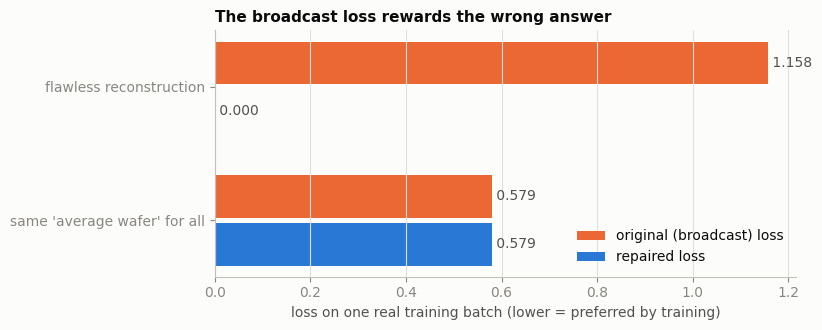

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
labels = ["flawless reconstruction", "same 'average wafer' for all"]
buggy_vals = [loss_demo["buggy_loss_perfect_reconstruction"], loss_demo["buggy_loss_batch_mean_output"]]
correct_vals = [loss_demo["correct_loss_perfect_reconstruction"], loss_demo["correct_loss_batch_mean_output"]]
ypos = np.arange(len(labels))
ax.barh(ypos - 0.18, buggy_vals, height=0.32, color=ORANGE, label="original (broadcast) loss")
ax.barh(ypos + 0.18, correct_vals, height=0.32, color=BLUE, label="repaired loss")
for y0, v in zip(ypos - 0.18, buggy_vals):
    ax.text(v, y0, f" {v:.3f}", va="center", color=INK_2)
for y0, v in zip(ypos + 0.18, correct_vals):
    ax.text(v, y0, f" {v:.3f}", va="center", color=INK_2)
ax.set_yticks(ypos, labels); ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("loss on one real training batch (lower = preferred by training)")
ax.set_title("The broadcast loss rewards the wrong answer")
ax.legend(loc="lower right")
save_fig(fig, "03_loss_bug")

**Reading the chart.** Under the original formula, a *flawless* reconstruction scores a
**higher** (worse) loss than outputting one identical "average wafer" for everybody. Gradient
descent therefore pushes the decoder toward the batch mean, exactly what the spread ratio above
shows. The autoencoder half of the "supervised autoencoder" was never learning to reconstruct.

### 3.3 · Defect C: Invariant blindness to the legacy probe station (cell 8)

The original treats PS-L sentinel `0.0` and error codes `100/200/300` as ordinary numbers:
they are averaged into the imputer, scaled with the real readings, and become extreme z-scores.

In [11]:
imp_mean_s1 = float(orig["imputer"].statistics_[1])
sc_mean, sc_std = orig["scaler"].mean_, orig["scaler"].scale_
blind = dict(
    imputer_mean_sensor_1_original=imp_mean_s1,
    true_mean_sensor_1_normal_wafers=legacy["sensor_1_normal_mean"],
    z_of_codes_in_original={str(int(c)): float((c - sc_mean[1]) / sc_std[1]) for c in LEGACY_CODES},
    z_of_sentinel_sensor_0_in_original=float((0.0 - sc_mean[0]) / sc_std[0]),
    sensor_0_normal_min=float(df.loc[~is_legacy_all, "sensor_0"].min()),
    sensor_0_normal_max=float(df.loc[~is_legacy_all, "sensor_0"].max()),
)
# The sentinel / codes also inflate the scaler's standard deviation, which squashes REAL readings.
for k in (0, 1):
    real_std = float(df.loc[~is_legacy_all, SENSOR_COLS[k]].std(ddof=0))
    blind[f"sensor_{k}_scaler_std_original"] = float(sc_std[k])
    blind[f"sensor_{k}_std_real_readings"] = real_std
    blind[f"sensor_{k}_real_spread_in_original_z"] = real_std / float(sc_std[k])
RESULTS["evidence_legacy_blindness"] = blind
print(json.dumps(blind, indent=2))

{
  "imputer_mean_sensor_1_original": 2280.5419065898914,
  "true_mean_sensor_1_normal_wafers": 2495.6859562455893,
  "z_of_codes_in_original": {
    "100": -3.234246920238864,
    "200": -3.085923840069456,
    "300": -2.937600759900048
  },
  "z_of_sentinel_sensor_0_in_original": -3.109051114244214,
  "sensor_0_normal_min": 2743.24,
  "sensor_0_normal_max": 3356.35,
  "sensor_0_scaler_std_original": 878.7621571379052,
  "sensor_0_std_real_readings": 74.3174502623071,
  "sensor_0_real_spread_in_original_z": 0.08457060839346588,
  "sensor_1_scaler_std_original": 674.2039059988804,
  "sensor_1_std_real_readings": 79.79277280850381,
  "sensor_1_real_spread_in_original_z": 0.11835109838215076
}


**What the numbers say.**
* `imputer_mean_sensor_1_original` vs `true_mean_sensor_1_normal_wafers`: the codes drag the
  mean that is used to fill missing values away from any real reading.
* `sensor_k_scaler_std_original` vs `sensor_k_std_real_readings`: mixing a sentinel/code cluster
  with readings in the thousands inflates σ, so genuine readings are squashed into a sliver of
  z-space (`sensor_k_real_spread_in_original_z`), so the real signal of both sensors is nearly erased.
* `z_of_codes_in_original`: all three codes collapse onto almost the same number, with an invented
  order (100 < 200 < 300), and the network cannot tell *which* fault the firmware reported.

## 4 · Repair

### 4.1 · Causal time split (train → validation → test)

Past wafers train the model, the next block picks the decision threshold, and the most
recent block is the untouched test set at its **natural** defect rate. Wafers sharing a
timestamp are never split across two sets.

In [12]:
def causal_cut(timestamps, fraction: float) -> int:
    """Row index where a split should happen, moved forward so equal timestamps stay together."""
    i = int(round(fraction * len(timestamps)))
    while 0 < i < len(timestamps) and timestamps[i] == timestamps[i - 1]:
        i += 1
    return i


def time_split(train_frac=SPLIT_FRACTIONS["train"], val_frac=SPLIT_FRACTIONS["val"]):
    a = causal_cut(TS, train_frac)
    b = causal_cut(TS, train_frac + val_frac)
    return np.arange(0, a), np.arange(a, b), np.arange(b, len(TS))


TR, VA, TE = time_split()
assert TS[TR].max() < TS[VA].min() and TS[VA].max() < TS[TE].min(), "time order violated"

split_info = {}
for name, idx in [("train", TR), ("val", VA), ("test", TE)]:
    split_info[name] = dict(rows=int(len(idx)), fails=int(y_all[idx].sum()),
                            prevalence=float(y_all[idx].mean()),
                            start=str(df["timestamp"].iloc[idx[0]]), end=str(df["timestamp"].iloc[idx[-1]]),
                            legacy_wafers=int(is_legacy_all[idx].sum()))
RESULTS["split"] = split_info
print(pd.DataFrame(split_info).T)

      rows fails prevalence                start                  end  \
train  940    76   0.080851  2008-07-19 11:55:00  2008-09-20 05:34:00   
val    314    11   0.035032  2008-09-20 06:08:00  2008-10-02 20:54:00   
test   313    17   0.054313  2008-10-02 21:32:00  2008-10-17 06:07:00   

      legacy_wafers  
train            79  
val              41  
test             26  


### 4.2 · Causal, legacy-aware preprocessing

`WaferPreprocessor` learns **everything** (which sensors to keep, means, standard deviations)
from the training wafers only, then applies those frozen numbers to any later wafer,
exactly what happens in production.

**Legacy PS-L handling (fixes Defect C):**
* `ps_l_legacy` = 1 when `sensor_0 == 0.0`: the station identity becomes an explicit feature.
* `ps_l_fw_code_100/200/300`: the firmware code becomes three yes/no (one-hot) columns.
* The sentinel and the codes are **removed from the continuous columns** before any mean or σ
  is computed, so they never enter scaling. On those wafers the two continuous slots are set to
  the neutral value 0 (the training mean in z-space); the flags above tell the model that no real
  measurement exists there. No value is pretended to be a measurement.

**Production hardening (not one of the three bugs, but found during the audit):**
* Sensors that are constant in training carry no information and are dropped.
* After a causal fit, some later wafers sit thousands of σ away (shown below). Values are
  capped at ±`CLIP_Z` σ so a single drifting sensor cannot dominate the network.

In [13]:
class WaferPreprocessor:
    """fit() on training wafers only; transform() any wafer using the frozen statistics."""

    def __init__(self, legacy_aware: bool = True, clip_z: float = CLIP_Z):
        self.legacy_aware = legacy_aware
        self.clip_z = clip_z

    def _prepare(self, frame: pd.DataFrame):
        X = frame[SENSOR_COLS].to_numpy(dtype=np.float64).copy()
        if not self.legacy_aware:                      # original behaviour: codes treated as numbers
            return X, np.empty((len(frame), 0))
        is_legacy = frame["sensor_0"].eq(0.0).to_numpy()
        codes = frame["sensor_1"].to_numpy()
        one_hot = [(is_legacy & (codes == c)).astype(float) for c in LEGACY_CODES]
        categorical = np.column_stack([is_legacy.astype(float), *one_hot])
        X[is_legacy, 0] = np.nan                       # sentinel 0.0 is not a measurement
        X[is_legacy, 1] = np.nan                       # error codes are not measurements
        return X, categorical

    def fit(self, frame: pd.DataFrame) -> "WaferPreprocessor":
        X, _ = self._prepare(frame)
        self.keep_ = pd.DataFrame(X).nunique(dropna=True).to_numpy() > 1   # drop constant sensors
        self.mean_ = np.nanmean(X[:, self.keep_], axis=0)
        self.std_ = np.nanstd(X[:, self.keep_], axis=0)
        kept = [c for c, k in zip(SENSOR_COLS, self.keep_) if k]
        extra = ["ps_l_legacy"] + [f"ps_l_fw_code_{int(c)}" for c in LEGACY_CODES] if self.legacy_aware else []
        self.feature_names_ = kept + extra
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        X, categorical = self._prepare(frame)
        Z = (X[:, self.keep_] - self.mean_) / self.std_
        Z = np.nan_to_num(Z, nan=0.0)                  # missing / neutralised -> training mean
        Z = np.clip(Z, -self.clip_z, self.clip_z)
        return np.hstack([Z, categorical]).astype(np.float32)


pre_main = WaferPreprocessor().fit(df.iloc[TR])

# How far do later wafers drift from the training statistics (before clipping)?
X_te_raw, _ = pre_main._prepare(df.iloc[TE])
z_unclipped = np.abs((X_te_raw[:, pre_main.keep_] - pre_main.mean_) / pre_main.std_)
RESULTS["preprocessing"] = dict(
    features_in=len(SENSOR_COLS), features_out=len(pre_main.feature_names_),
    sensors_dropped_constant_in_train=int((~pre_main.keep_).sum()),
    test_max_abs_z_before_clip=float(np.nanmax(z_unclipped)),
    test_cells_beyond_clip=int(np.nansum(z_unclipped > CLIP_Z)),
    test_cells_total=int(np.isfinite(z_unclipped).sum()),
    clip_z=CLIP_Z,
)
print(json.dumps(RESULTS["preprocessing"], indent=2))

{
  "features_in": 590,
  "features_out": 472,
  "sensors_dropped_constant_in_train": 122,
  "test_max_abs_z_before_clip": 37152.08506283129,
  "test_cells_beyond_clip": 612,
  "test_cells_total": 139463,
  "clip_z": 5.0
}


### 4.3 · Shape-safe loss (fixes Defect B)

The target is flattened to the same `[B, F]` layout the model reconstructs, and an `assert`
stops training immediately if shapes ever disagree, so a silent bug becomes a loud one.
The original formula is kept (clearly named) only so §7 can measure its damage.

In [14]:
def reconstruction_loss(reconstructed: torch.Tensor, batch_x: torch.Tensor) -> torch.Tensor:
    target = batch_x.flatten(start_dim=1)              # [B, 1, F] -> [B, F]
    assert reconstructed.shape == target.shape, f"{tuple(reconstructed.shape)} vs {tuple(target.shape)}"
    return torch.mean((reconstructed - target) ** 2)


def original_buggy_reconstruction_loss(reconstructed, batch_x):
    return torch.mean((reconstructed - batch_x) ** 2)  # broadcasts to [B, B, F] - ablation only


def train_model(X_train, y_train, seed: int, loss_bug: bool = False):
    """Same optimiser, schedule and epochs as the original; only the loss is repaired."""
    set_seed(seed)
    loader = make_loader(X_train, y_train.astype(np.int64), shuffle=True, seed=seed)
    model = WaferSAE(X_train.shape[1], HP["hidden"], HP["latent"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=HP["epochs"])
    bce = nn.BCEWithLogitsLoss()
    recon_fn = original_buggy_reconstruction_loss if loss_bug else reconstruction_loss
    history = {"recon": [], "clf": []}
    for _ in range(HP["epochs"]):
        model.train()
        sums, n = {"recon": 0.0, "clf": 0.0}, 0
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            reconstructed, logits, _ = model(batch_x)
            assert logits.shape == batch_y.shape       # classifier shapes must match too
            recon_loss = recon_fn(reconstructed, batch_x)
            clf_loss = bce(logits, batch_y)
            loss = recon_loss + HP["lambda_clf"] * clf_loss
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
            sums["recon"] += recon_loss.item(); sums["clf"] += clf_loss.item(); n += 1
        sched.step()
        for k in history:
            history[k].append(sums[k] / n)
    return model, history


@torch.no_grad()
def predict_proba(model, X: np.ndarray) -> np.ndarray:
    model.eval()
    _, logits, _ = model(torch.from_numpy(X).float().to(DEVICE))
    return torch.sigmoid(logits).cpu().numpy()


@torch.no_grad()
def reconstruction_quality(model, X: np.ndarray) -> dict:
    """True per-wafer reconstruction error, and how much reconstructions vary between wafers."""
    model.eval()
    x = torch.from_numpy(X).float().to(DEVICE)
    r = model(x)[0]
    return dict(recon_mse=float(torch.mean((r - x) ** 2)),
                recon_spread_ratio=float(r.std(dim=0).mean() / x.std(dim=0).mean()))

### 4.4 · Threshold chosen on validation, metrics computed on test

The original used a fixed 0.5 cut-off. With a 6.6 % defect rate, 0.5 is arbitrary. We pick the
threshold that maximises F1 on the **validation** block, freeze it, and only then look at test.

**Why these metrics?** At natural prevalence, accuracy and ROC-AUC look good even for weak models
(they are dominated by the many passing wafers). We lead with **precision / recall / F1** at the
frozen threshold (what operators experience: false alarms vs. missed excursions) and
**PR-AUC (average precision)**, whose no-skill baseline equals the defect rate.

In [15]:
def pick_threshold(y_val: np.ndarray, p_val: np.ndarray) -> float:
    assert y_val.sum() > 0, "validation block has no defects; cannot tune a threshold"
    precision, recall, thresholds = precision_recall_curve(y_val, p_val)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return float(thresholds[np.argmax(f1[:-1])])      # last PR point has no threshold


def evaluate(y: np.ndarray, p: np.ndarray, threshold: float) -> dict:
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=int(len(y)), n_defects=int(y.sum()), prevalence=float(y.mean()),
                threshold=float(threshold),
                precision=float(precision_score(y, pred, zero_division=0)),
                recall=float(recall_score(y, pred, zero_division=0)),
                f1=float(f1_score(y, pred, zero_division=0)),
                mcc=float(matthews_corrcoef(y, pred)),
                ap=float(average_precision_score(y, p)),
                roc_auc=float(roc_auc_score(y, p)),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

### 4.5 · One configurable experiment

Every switch in `Config` corresponds to one defect. The default is the repaired pipeline;
flipping a switch re-introduces exactly one original bug. §7 uses this to attribute the fake score.

In [16]:
@dataclass(frozen=True)
class Config:
    name: str = "Repaired pipeline"
    split: str = "time"              # "time" | "random"
    fit_preproc_on: str = "train"    # "train" | "all"   (all = leakage)
    smote: str = "train_only"        # "train_only" | "before_split"
    loss_bug: bool = False           # True = original broadcast loss
    legacy_aware: bool = True        # False = original PS-L blindness
    threshold: str = "val_f1"        # "val_f1" | "fixed_0.5"


def random_split(seed: int, y: np.ndarray = y_all):
    """Stratified random split with the same train / val / test shares as SPLIT_FRACTIONS."""
    idx = np.arange(len(y))
    rest_share = 1 - SPLIT_FRACTIONS["train"]
    tr, rest = train_test_split(idx, test_size=rest_share, stratify=y, random_state=seed)
    va, te = train_test_split(rest, test_size=1 - SPLIT_FRACTIONS["val"] / rest_share, stratify=y[rest],
                              random_state=seed)
    return tr, va, te


def run_experiment(cfg: Config, seed: int = SEED, split=None, keep=False) -> dict:
    set_seed(seed)
    if cfg.smote == "before_split":
        # Original order: preprocess everything, oversample everything, then split randomly.
        assert cfg.split == "random", "SMOTE-before-split only exists with a random split"
        pre = WaferPreprocessor(cfg.legacy_aware).fit(df)
        X_bal, y_bal = SMOTE(random_state=seed).fit_resample(pre.transform(df), y_all)
        tr, va, te = random_split(seed, y_bal)
        X_tr, y_tr, X_va, y_va, X_te, y_te = X_bal[tr], y_bal[tr], X_bal[va], y_bal[va], X_bal[te], y_bal[te]
        test_rows = None
    else:
        if split is not None:
            tr, va, te = split
        else:
            tr, va, te = (TR, VA, TE) if cfg.split == "time" else random_split(seed)
        pre = WaferPreprocessor(cfg.legacy_aware).fit(df if cfg.fit_preproc_on == "all" else df.iloc[tr])
        X_tr, X_va, X_te = (pre.transform(df.iloc[i]) for i in (tr, va, te))
        y_va, y_te = y_all[va], y_all[te]
        X_tr, y_tr = SMOTE(random_state=seed).fit_resample(X_tr, y_all[tr])   # training rows only
        test_rows = te

    model, history = train_model(X_tr, y_tr, seed, loss_bug=cfg.loss_bug)
    p_va, p_te = predict_proba(model, X_va), predict_proba(model, X_te)
    thr = 0.5 if cfg.threshold == "fixed_0.5" else pick_threshold(y_va, p_va)
    out = dict(config=cfg.name, seed=seed, **evaluate(y_te, p_te, thr), **reconstruction_quality(model, X_te))
    if keep:
        out["_objects"] = dict(model=model, pre=pre, p_te=p_te, y_te=y_te, p_va=p_va, y_va=y_va,
                               test_rows=test_rows, history=history, X_tr=X_tr, y_tr=y_tr, X_va=X_va, X_te=X_te)
    return out

## 5 · Honest evaluation at natural prevalence

### 5.1 · The repaired model on the most recent 20 % of wafers

In [17]:
main = run_experiment(Config(), seed=SEED, keep=True)
objs = main.pop("_objects")
RESULTS["repaired_test"] = main
RESULTS["repaired_training"] = dict(
    final_train_recon_loss=objs["history"]["recon"][-1], final_train_clf_loss=objs["history"]["clf"][-1],
    val_score_median=float(np.median(objs["p_va"])), val_score_max=float(objs["p_va"].max()),
    test_score_median=float(np.median(objs["p_te"])), test_score_max=float(objs["p_te"].max()),
    test_wafers_scored_at_least_0_5=int((objs["p_te"] >= 0.5).sum()),
    test_defects_scored_at_least_0_5=int(((objs["p_te"] >= 0.5) & (objs["y_te"] == 1)).sum()),
)
print(json.dumps(main, indent=2))
print(json.dumps(RESULTS["repaired_training"], indent=2))

{
  "config": "Repaired pipeline",
  "seed": 1337,
  "n": 313,
  "n_defects": 17,
  "prevalence": 0.054313099041533544,
  "threshold": 0.00036151628592051566,
  "precision": 0.14285714285714285,
  "recall": 0.11764705882352941,
  "f1": 0.12903225806451613,
  "mcc": 0.08453991315832947,
  "ap": 0.09521546287736635,
  "roc_auc": 0.6162559618441972,
  "tn": 284,
  "fp": 12,
  "fn": 15,
  "tp": 2,
  "recon_mse": 0.7141157984733582,
  "recon_spread_ratio": 0.4933823347091675
}
{
  "final_train_recon_loss": 0.2046099509353991,
  "final_train_clf_loss": 0.0002524885623845168,
  "val_score_median": 6.181510980241e-05,
  "val_score_max": 0.9994997978210449,
  "test_score_median": 4.4205639824212994e-06,
  "test_score_max": 0.994840681552887,
  "test_wafers_scored_at_least_0_5": 2,
  "test_defects_scored_at_least_0_5": 0
}


**Why is the chosen threshold so small?** Look at `final_train_clf_loss`: on the SMOTE-balanced
training set the classifier drives its loss almost to zero, i.e. it memorises the training wafers
and becomes over-confident. On new wafers most scores collapse towards 0 (`test_score_median`),
while a few wafers get confident spikes (`test_score_max`) that are mostly *not* defects
(compare `test_wafers_scored_at_least_0_5` with `test_defects_scored_at_least_0_5`). The F1-best
cut-off on validation therefore lands far below 0.5. §7 shows what a fixed 0.5 cut-off does.

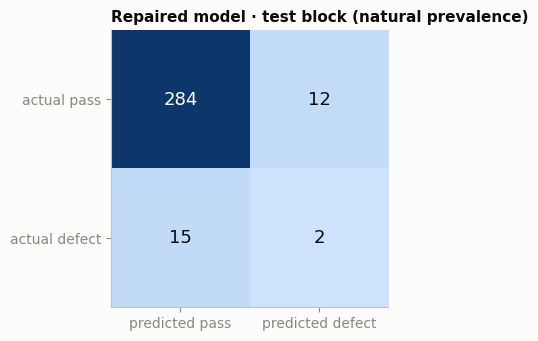

In [18]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
cm = np.array([[main["tn"], main["fp"]], [main["fn"], main["tp"]]])
ax.imshow(cm, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("b", BLUES))
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v}", ha="center", va="center", fontsize=13,
            color="white" if v > cm.max() * 0.5 else INK)
ax.set_xticks([0, 1], ["predicted pass", "predicted defect"])
ax.set_yticks([0, 1], ["actual pass", "actual defect"])
ax.grid(False)
ax.set_title("Repaired model · test block (natural prevalence)")
save_fig(fig, "05_confusion_matrix")

### 5.2 · Uncertainty: bootstrap intervals and seed-to-seed variation

The test block holds only a small number of defects, so a single F1 is noisy. We report
(a) a 95 % bootstrap interval (resampling test wafers 2 000 times with the threshold frozen) and
(b) the spread across five training seeds.

In [19]:
def bootstrap_ci(y, p, threshold, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    f1s, aps = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0:
            continue
        f1s.append(f1_score(y[i], (p[i] >= threshold).astype(int), zero_division=0))
        aps.append(average_precision_score(y[i], p[i]))
    q = lambda a: [float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))]
    return dict(f1_ci95=q(f1s), ap_ci95=q(aps), n_boot_used=len(f1s))


RESULTS["repaired_test_bootstrap"] = bootstrap_ci(objs["y_te"], objs["p_te"], main["threshold"])
print(json.dumps(RESULTS["repaired_test_bootstrap"], indent=2))

seed_runs = [main] + [run_experiment(Config(), seed=s) for s in EVAL_SEEDS if s != SEED]
seed_df = pd.DataFrame(seed_runs)[["seed", "threshold", "precision", "recall", "f1", "ap", "roc_auc"]]
RESULTS["repaired_test_seeds"] = dict(
    runs=seed_df.to_dict(orient="records"),
    mean={k: float(seed_df[k].mean()) for k in ["precision", "recall", "f1", "ap", "roc_auc"]},
    std={k: float(seed_df[k].std(ddof=1)) for k in ["precision", "recall", "f1", "ap", "roc_auc"]},
)
seed_df.round(4)

{
  "f1_ci95": [
    0.0,
    0.29411764705882354
  ],
  "ap_ci95": [
    0.04889108201077808,
    0.23195546134195014
  ],
  "n_boot_used": 2000
}


,seed,threshold,precision,recall,f1,ap,roc_auc
0,1337,0.0004,0.1429,0.1176,0.1290,0.0952,0.6163
1,7,0.0000,0.0563,0.7059,0.1043,0.0727,0.5692
2,42,0.0000,0.0714,0.6471,0.1287,0.0824,0.5835
3,2024,0.0000,0.0510,0.5882,0.0939,0.0593,0.5169
4,31337,0.0001,0.1290,0.2353,0.1667,0.1157,0.6049


### 5.3 · Reference points: is the deep model earning its complexity?

* **No-skill:** a model that guesses has PR-AUC equal to the defect rate.
* **Logistic regression** on the same causal features (regularisation strength chosen on validation).

If a one-layer linear model matches the autoencoder, that is a finding the release board should hear.

In [20]:
best = None
for C in [0.001, 0.01, 0.1, 1.0]:
    lr_model = LogisticRegression(C=C, max_iter=5000, class_weight="balanced")
    lr_model.fit(objs["X_tr"], objs["y_tr"])
    ap_val = average_precision_score(objs["y_va"], lr_model.predict_proba(objs["X_va"])[:, 1])
    if best is None or ap_val > best[0]:
        best = (ap_val, C, lr_model)
_, best_C, lr_model = best
p_va_lr = lr_model.predict_proba(objs["X_va"])[:, 1]
p_te_lr = lr_model.predict_proba(objs["X_te"])[:, 1]
RESULTS["baseline_logreg"] = dict(C=best_C, **evaluate(objs["y_te"], p_te_lr, pick_threshold(objs["y_va"], p_va_lr)))
RESULTS["baseline_no_skill_ap"] = float(objs["y_te"].mean())
print(json.dumps(RESULTS["baseline_logreg"], indent=2))

{
  "C": 0.001,
  "n": 313,
  "n_defects": 17,
  "prevalence": 0.054313099041533544,
  "threshold": 0.2887495055217467,
  "precision": 0.07407407407407407,
  "recall": 0.5882352941176471,
  "f1": 0.13157894736842105,
  "mcc": 0.07593452382034947,
  "ap": 0.08844815811018558,
  "roc_auc": 0.6136724960254372,
  "tn": 171,
  "fp": 125,
  "fn": 7,
  "tp": 10
}


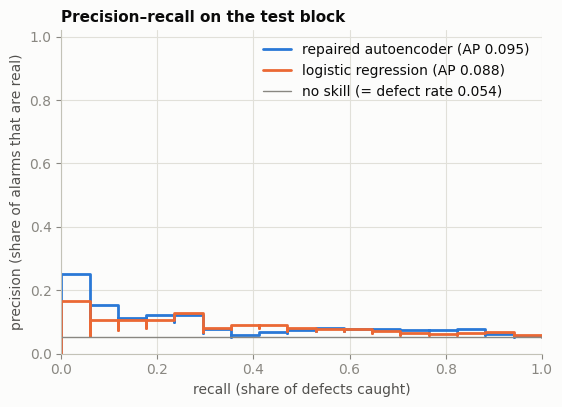

In [21]:
def pr_points(y, p):
    precision, recall, _ = precision_recall_curve(y, p)
    return recall[:-1], precision[:-1]     # last point is sklearn's convention (recall 0, precision 1), not data


fig, ax = plt.subplots(figsize=(6.2, 4.2))
r, pr = pr_points(objs["y_te"], objs["p_te"])
ax.step(r, pr, where="post", color=BLUE, label=f"repaired autoencoder (AP {main['ap']:.3f})")
r2, pr2 = pr_points(objs["y_te"], p_te_lr)
ax.step(r2, pr2, where="post", color=ORANGE, label=f"logistic regression (AP {RESULTS['baseline_logreg']['ap']:.3f})")
ax.axhline(RESULTS["baseline_no_skill_ap"], color=MUTED, linewidth=1,
           label=f"no skill (= defect rate {RESULTS['baseline_no_skill_ap']:.3f})")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("recall (share of defects caught)"); ax.set_ylabel("precision (share of alarms that are real)")
ax.set_title("Precision–recall on the test block")
ax.legend(loc="upper right")
save_fig(fig, "06_precision_recall")

RESULTS["pr_curves"] = {
    "repaired": {"recall": r.tolist(), "precision": pr.tolist()},
    "logreg": {"recall": r2.tolist(), "precision": pr2.tolist()},
}